# Subquestion 2: Which characteristics are associated with more crashes?

In [38]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
import warnings
warnings.filterwarnings("ignore")  

os.makedirs("figures", exist_ok=True)  

df = pd.read_csv("cleaned_data/05_analysis_ready_zh_motorways.csv")


df = df[df["HAS_TRAFFIC_DATA"] == 1]
df = df.dropna(subset=["AVG_DAILY_TRAFFIC", "HGV_SHARE_PCT", "NIGHT_TRAFFIC_SHARE_PCT"])

type_groups = {
    "HR": "Main carriageway",
    "OPR": "On-ramp",
    "AFR": "Off-ramp",
    "VBR": "Connector",
    "VBD": "Connector",
    "VBS": "Connector",
    "VBK": "Connector",
    "VBI": "Connector",
}
df["CARRIAGEWAY_GROUP"] = df["CARRIAGEWAY_TYPE_BEGIN"].map(type_groups)
df = df.dropna(subset=["CARRIAGEWAY_GROUP"]).copy()

print("Sections used:", len(df))
print("Crashes on these sections:", df["TOTAL_CRASHES"].sum())

df.groupby("CARRIAGEWAY_GROUP")[["ROAD_LENGTH_M", "AVG_DAILY_TRAFFIC"]].mean().round(0)

Sections used: 1208
Crashes on these sections: 7282


,ROAD_LENGTH_M,AVG_DAILY_TRAFFIC
CARRIAGEWAY_GROUP,,
Connector,642.0,19483.0
Main carriageway,1408.0,43856.0
Off-ramp,315.0,7712.0
On-ramp,329.0,7963.0


In [39]:

df["LN_TRAFFIC"] = np.log(df["AVG_DAILY_TRAFFIC"])
df["LN_LENGTH_KM"] = np.log(df["ROAD_LENGTH_M"] / 1000)

formula = ("TOTAL_CRASHES ~ LN_TRAFFIC + LN_LENGTH_KM"
           " + C(CARRIAGEWAY_GROUP, Treatment('Main carriageway'))"
           " + HGV_SHARE_PCT + NIGHT_TRAFFIC_SHARE_PCT")


def fit_nb(formula, data):
    start = smf.poisson(formula, data=data).fit(disp=0).params
    start["alpha"] = 0.5
    model = smf.negativebinomial(formula, data=data).fit(start_params=start, maxiter=1000, disp=0)
    print("converged:", model.mle_retvals["converged"])
    return model


print("Mean crashes per section:", round(df["TOTAL_CRASHES"].mean(), 1))
print("Variance:", round(df["TOTAL_CRASHES"].var(), 1))
print("Sections with 0 crashes:", (df["TOTAL_CRASHES"] == 0).sum())

poisson_model = smf.poisson(formula, data=df).fit(disp=0)
nb_model = fit_nb(formula, df)
print("AIC Poisson:", round(poisson_model.aic, 1))
print("AIC Negative Binomial:", round(nb_model.aic, 1))  

Mean crashes per section: 6.0
Variance: 174.9
Sections with 0 crashes: 440
converged: True
AIC Poisson: 7255.6
AIC Negative Binomial: 4979.1


In [40]:
ci = nb_model.conf_int()

for variable, text in [("LN_TRAFFIC", "traffic"), ("LN_LENGTH_KM", "length")]:
    b = nb_model.params[variable]
    print(f"10% more {text} -> {b * 10:.1f}% more crashes "
          f"(coefficient {b:.2f}, 95% CI {ci.loc[variable, 0]:.2f} to {ci.loc[variable, 1]:.2f})")

names = {
    "C(CARRIAGEWAY_GROUP, Treatment('Main carriageway'))[T.Connector]": "Connector (vs main carriageway)",
    "C(CARRIAGEWAY_GROUP, Treatment('Main carriageway'))[T.On-ramp]": "On-ramp (vs main carriageway)",
    "C(CARRIAGEWAY_GROUP, Treatment('Main carriageway'))[T.Off-ramp]": "Off-ramp (vs main carriageway)",
    "HGV_SHARE_PCT": "HGV share (+1 %-point)",
    "NIGHT_TRAFFIC_SHARE_PCT": "Night traffic share (+1 %-point)",
}

results = pd.DataFrame({
    "IRR": np.exp(nb_model.params),
    "CI_low": np.exp(ci[0]),
    "CI_high": np.exp(ci[1]),
    "p_value": nb_model.pvalues,
})
results = results.loc[list(names.keys())]
results.index = list(names.values())
results["change_pct"] = ((results["IRR"] - 1) * 100).round(1)
results.round(3)

10% more traffic -> 8.2% more crashes (coefficient 0.82, 95% CI 0.70 to 0.93)
10% more length -> 6.9% more crashes (coefficient 0.69, 95% CI 0.61 to 0.77)


,IRR,CI_low,CI_high,p_value,change_pct
Connector (vs main carriageway),0.331,0.276,0.398,0.000,-66.9
On-ramp (vs main carriageway),0.811,0.615,1.069,0.137,-18.9
Off-ramp (vs main carriageway),0.840,0.636,1.108,0.217,-16.0
HGV share (+1 %-point),0.999,0.989,1.009,0.809,-0.1
Night traffic share (+1 %-point),1.026,1.001,1.053,0.043,2.6


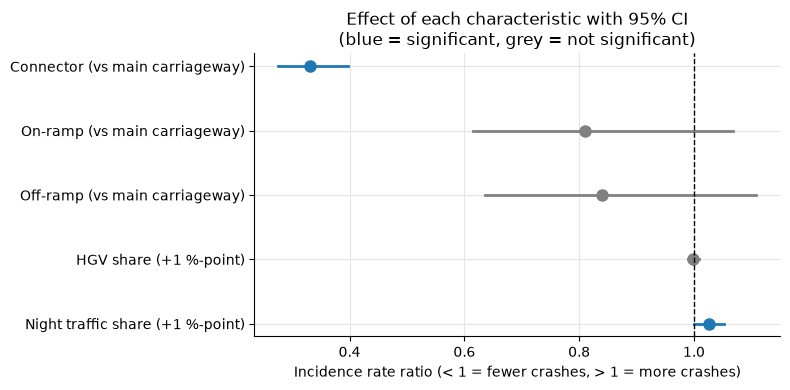

In [41]:
fig, ax = plt.subplots(figsize=(8, 4))
for i, name in enumerate(results.index):
    row = results.loc[name]
    if row["p_value"] < 0.05:
        color = "tab:blue"
    else:
        color = "grey"
    ax.plot([row["CI_low"], row["CI_high"]], [i, i], color=color, linewidth=2)  # 95% CI
    ax.plot(row["IRR"], i, "o", color=color, markersize=8)                       # IRR
ax.axvline(1, color="black", linestyle="--", linewidth=1)
ax.set_yticks(range(len(results)))
ax.set_yticklabels(results.index)
ax.invert_yaxis()
ax.set_xlabel("Incidence rate ratio (< 1 = fewer crashes, > 1 = more crashes)")
ax.set_title("Effect of each characteristic with 95% CI\n(blue = significant, grey = not significant)")
plt.tight_layout()
plt.savefig("figures/sq2_irr_plot.png", dpi=150, bbox_inches="tight")
plt.show()

In [42]:
controls_model = fit_nb("TOTAL_CRASHES ~ LN_TRAFFIC + LN_LENGTH_KM", df)

lr = 2 * (nb_model.llf - controls_model.llf)
p_lr = stats.chi2.sf(lr, 5)   # 5 extra parameters: 3 carriageway groups + HGV + night
print(f"LR test: LR = {lr:.1f}, p = {p_lr:.4f}")
print("AIC controls only:", round(controls_model.aic, 1))
print("AIC with characteristics:", round(nb_model.aic, 1))

converged: True
LR test: LR = 160.7, p = 0.0000
AIC controls only: 5129.9
AIC with characteristics: 4979.1


Typical section: 15350.0 vehicles/day, 508.0 m


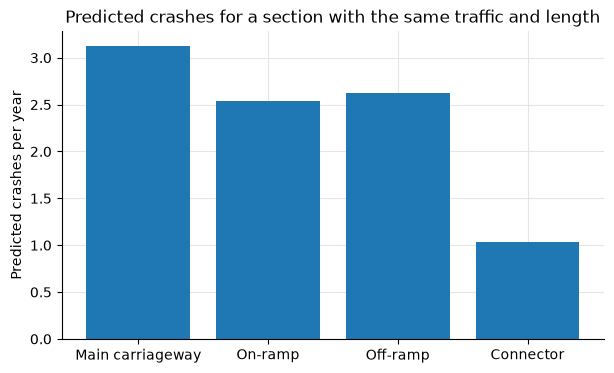

,CARRIAGEWAY_GROUP,PREDICTED_CRASHES
0,Main carriageway,3.13
1,On-ramp,2.54
2,Off-ramp,2.63
3,Connector,1.04


In [43]:
groups = ["Main carriageway", "On-ramp", "Off-ramp", "Connector"]

# same traffic, length, HGV share and night share for all four, only the type changes
typical = pd.DataFrame({
    "CARRIAGEWAY_GROUP": groups,
    "LN_TRAFFIC": np.log(df["AVG_DAILY_TRAFFIC"].median()),
    "LN_LENGTH_KM": np.log(df["ROAD_LENGTH_M"].median() / 1000),
    "HGV_SHARE_PCT": df["HGV_SHARE_PCT"].median(),
    "NIGHT_TRAFFIC_SHARE_PCT": df["NIGHT_TRAFFIC_SHARE_PCT"].median(),
})
typical["PREDICTED_CRASHES"] = nb_model.predict(typical)
print("Typical section:", df["AVG_DAILY_TRAFFIC"].median(), "vehicles/day,", df["ROAD_LENGTH_M"].median(), "m")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(typical["CARRIAGEWAY_GROUP"], typical["PREDICTED_CRASHES"], color="tab:blue")
ax.set_ylabel("Predicted crashes per year")
ax.set_title("Predicted crashes for a section with the same traffic and length")
plt.savefig("figures/sq2_predicted_crashes.png", dpi=150, bbox_inches="tight")
plt.show()

typical[["CARRIAGEWAY_GROUP", "PREDICTED_CRASHES"]].round(2)